In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('/project/src')

from processing import grouped_barplot, grouped_lineplot

In [2]:
df = pd.read_csv("/project/data/hotel-booking-demand/hotel_bookings.csv")

In [3]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [4]:
missing = df.isna().sum()
missing[missing != 0]

children         4
country        488
agent        16340
company     112593
dtype: int64

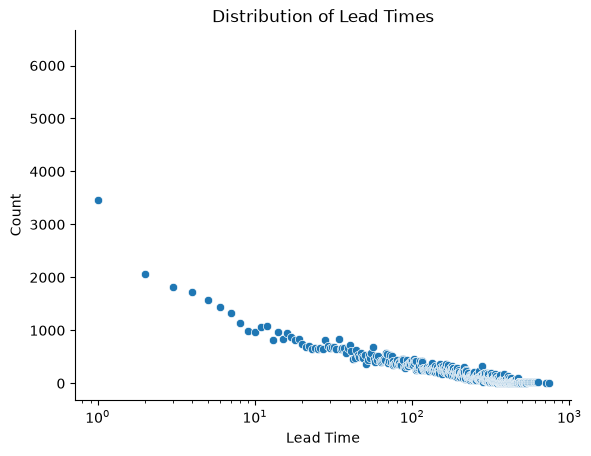

In [5]:
ax = sns.scatterplot(
    df['lead_time'].value_counts().sort_index().reset_index(),
    x = 'lead_time',
    y = 'count'
)
ax.set_xscale('log')
ax.set_title('Distribution of Lead Times')
ax.set_xlabel('Lead Time')
ax.set_ylabel('Count')
sns.despine(ax=ax)
plt.show()

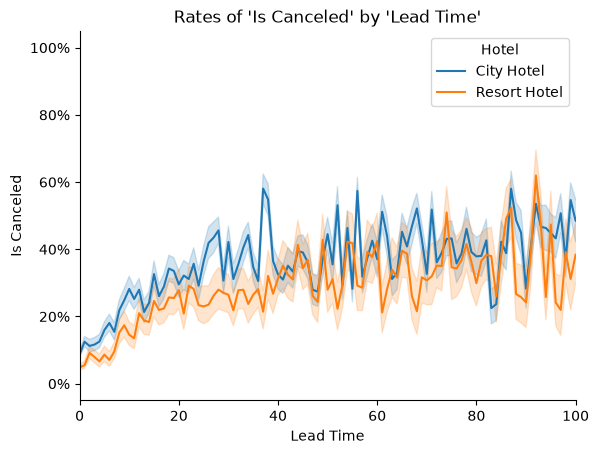

In [6]:
grouped_lineplot(df, 'lead_time', 'is_canceled', 'hotel', xlim=(0, 100))

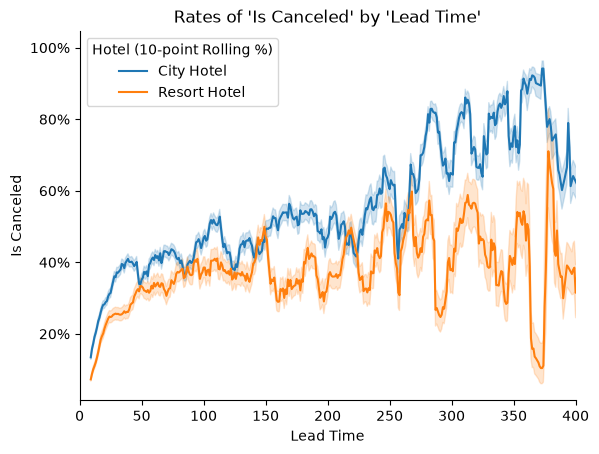

In [7]:
grouped_lineplot(df, 'lead_time', 'is_canceled', 'hotel', rolling_period=10, xlim=(0, 400))

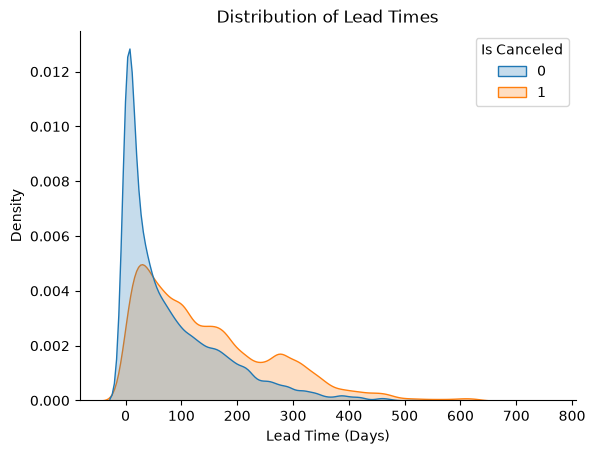

In [8]:
ax = sns.kdeplot(
    df,
    x='lead_time',
    hue='is_canceled',
    common_norm=False,
    fill=True
)
ax.set_title('Distribution of Lead Times')
ax.get_legend().set_title('Is Canceled')
ax.set_xlabel('Lead Time (Days)')
sns.despine(ax=ax)
plt.show()

In [9]:
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str)
    + '-'
    + df['arrival_date_month']
    + '-'
    + df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)
df['arrival_month_and_day'] = pd.to_datetime(
    '2000-' + df['arrival_date'].dt.strftime('%m-%d'),
    format='%Y-%m-%d'
)

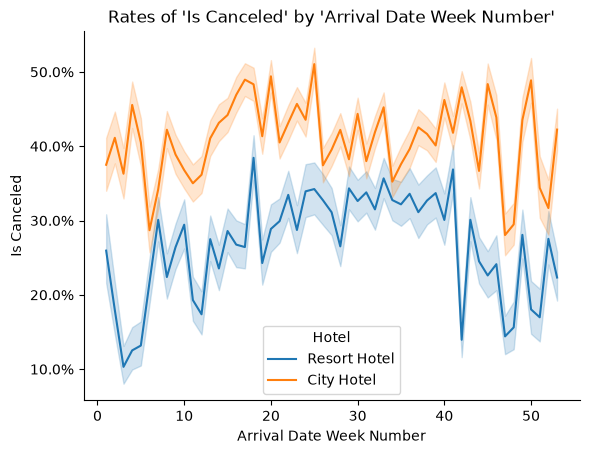

In [10]:
grouped_lineplot(df, 'arrival_date_week_number', 'is_canceled', 'hotel')

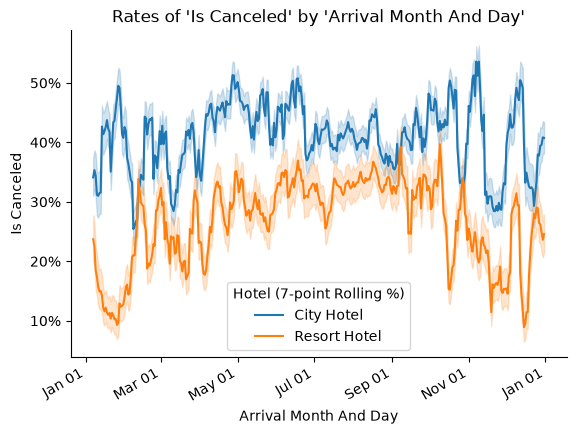

In [11]:
grouped_lineplot(df, 'arrival_month_and_day', 'is_canceled', 'hotel', rolling_period=7, remove_year=True)

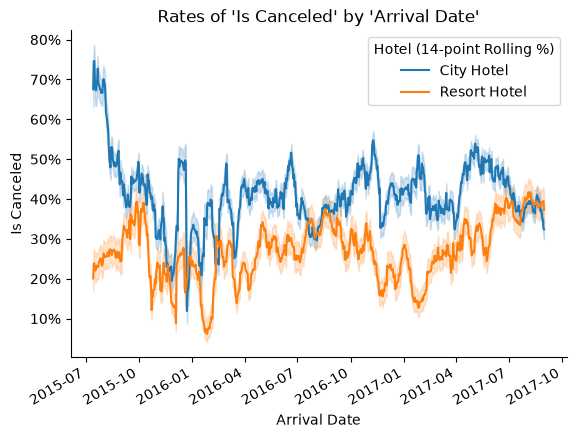

In [12]:
grouped_lineplot(df, 'arrival_date', 'is_canceled', 'hotel', rolling_period=14)

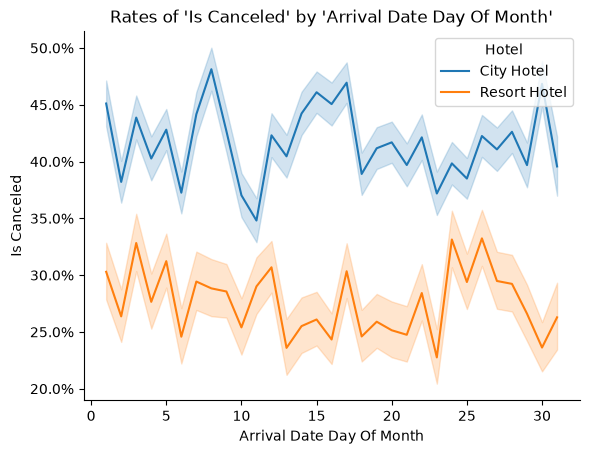

In [13]:
grouped_lineplot(df, 'arrival_date_day_of_month', 'is_canceled', 'hotel')

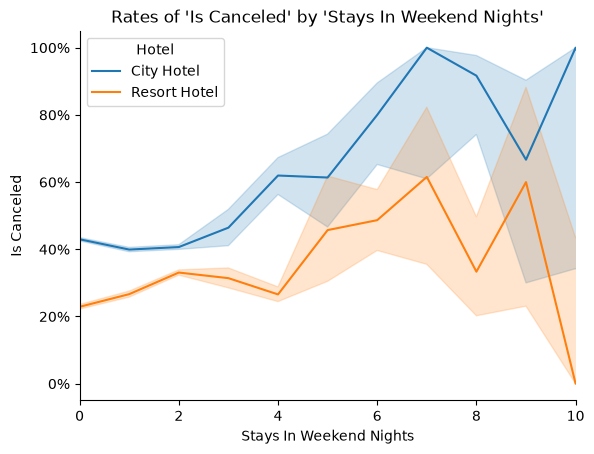

In [14]:
grouped_lineplot(df, 'stays_in_weekend_nights', 'is_canceled', 'hotel', xlim=(0, 10))

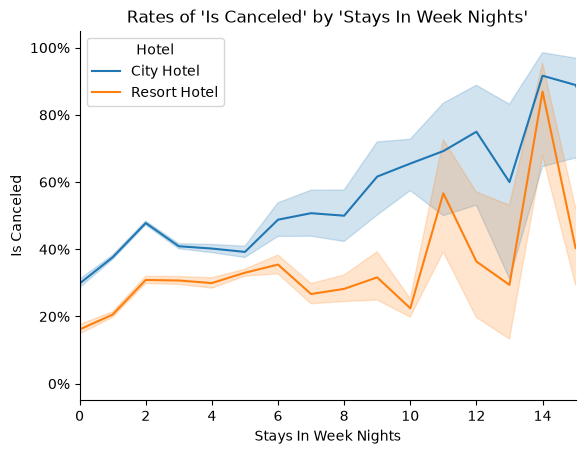

In [15]:
grouped_lineplot(df, 'stays_in_week_nights', 'is_canceled', 'hotel', xlim=(0, 15))

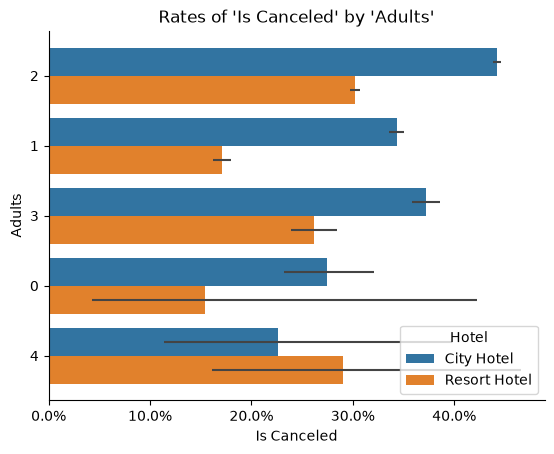

In [16]:
grouped_barplot(df, 'adults', 'is_canceled', 'hotel', categories=[0, 1, 2, 3, 4])

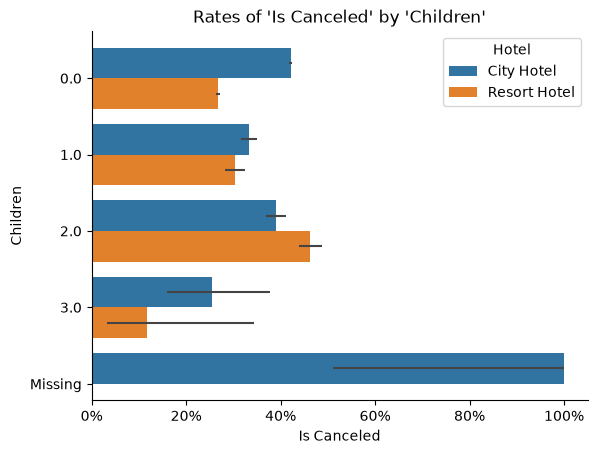

In [17]:
grouped_barplot(df, 'children', 'is_canceled', 'hotel', categories=[0, 1, 2, 3, 'Missing'])

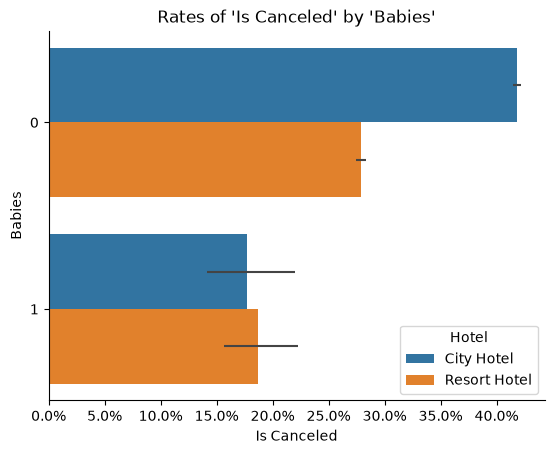

In [18]:
grouped_barplot(df, 'babies', 'is_canceled', 'hotel', categories=[0, 1])

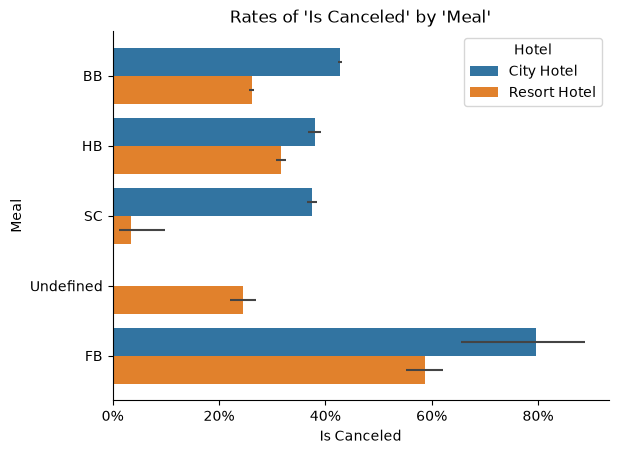

In [19]:
grouped_barplot(df, 'meal', 'is_canceled', 'hotel')

In [20]:
countries = df['country'].value_counts()
frequent_countries = countries[countries > 1000].index.tolist()

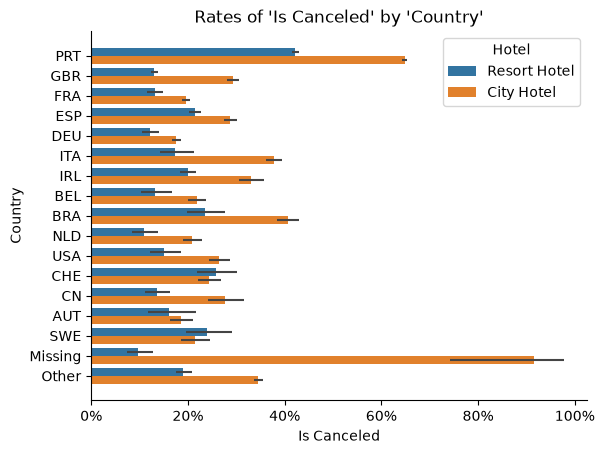

In [21]:
grouped_barplot(df, 'country', 'is_canceled', 'hotel', categories=frequent_countries + ['Missing'], other='Other')

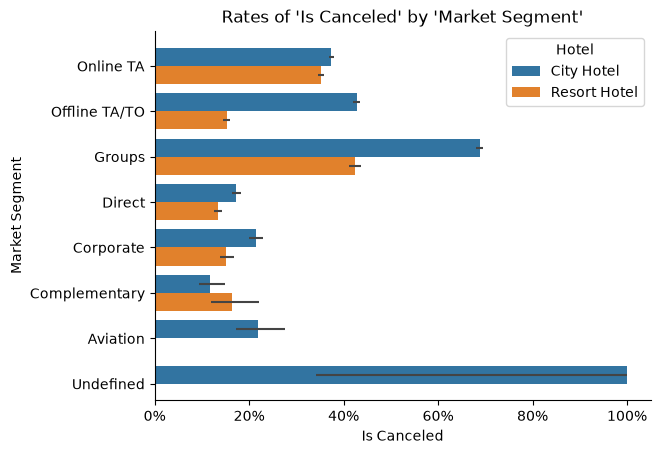

In [22]:
grouped_barplot(df, 'market_segment', 'is_canceled', 'hotel')

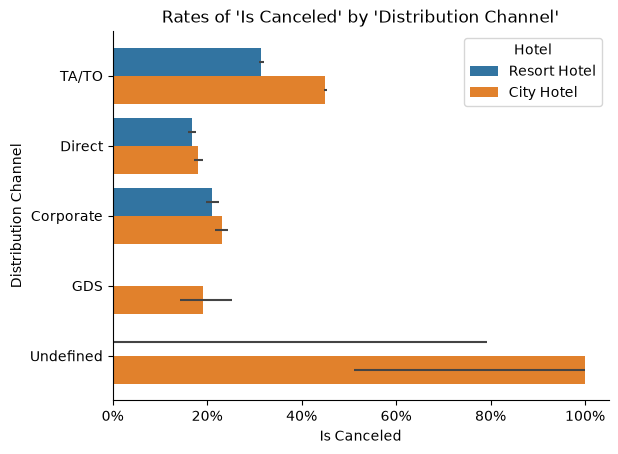

In [23]:
grouped_barplot(df, 'distribution_channel', 'is_canceled', 'hotel')

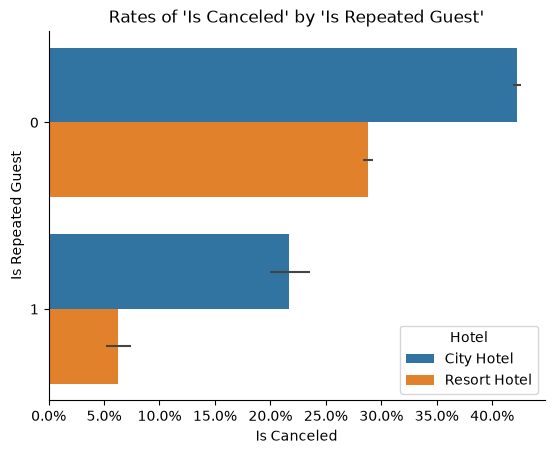

In [24]:
grouped_barplot(df, 'is_repeated_guest', 'is_canceled', 'hotel')

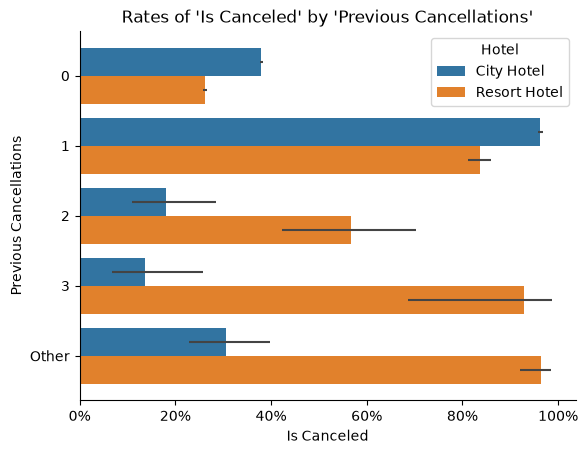

In [25]:
grouped_barplot(df, 'previous_cancellations', 'is_canceled', 'hotel', categories=[0, 1, 2, 3], other='Other')

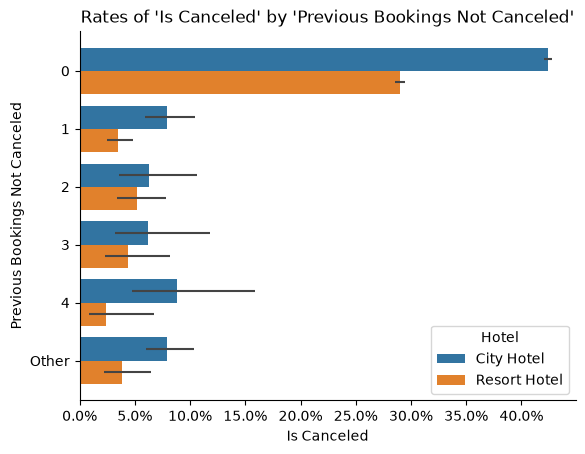

In [26]:
grouped_barplot(df, 'previous_bookings_not_canceled', 'is_canceled', 'hotel', categories=[0, 1, 2, 3, 4], other='Other')

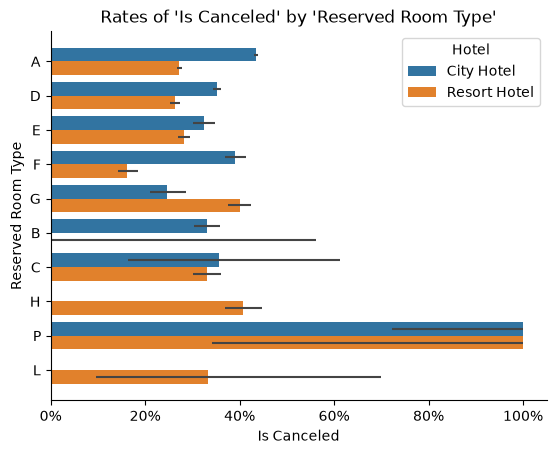

In [27]:
grouped_barplot(df, 'reserved_room_type', 'is_canceled', 'hotel')

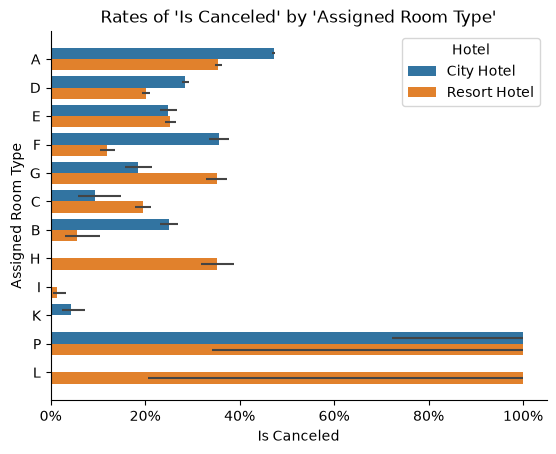

In [28]:
grouped_barplot(df, 'assigned_room_type', 'is_canceled', 'hotel')

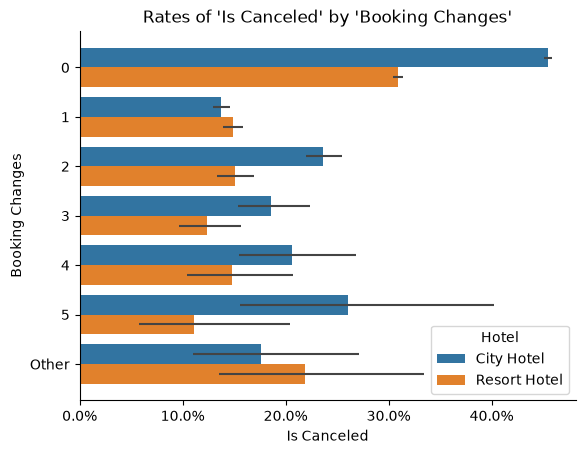

In [29]:
grouped_barplot(df, 'booking_changes', 'is_canceled', 'hotel', categories=[0, 1, 2, 3, 4, 5], other='Other')

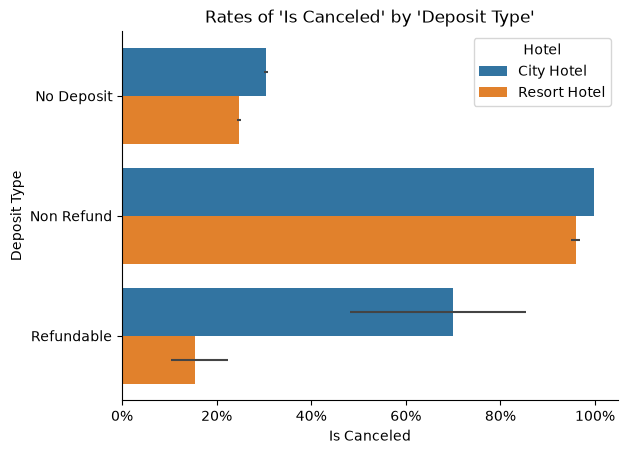

In [30]:
grouped_barplot(df, 'deposit_type', 'is_canceled', 'hotel')

In [31]:
agents = df['agent'].value_counts()
frequent_agents = agents[agents > 1000].index.tolist()

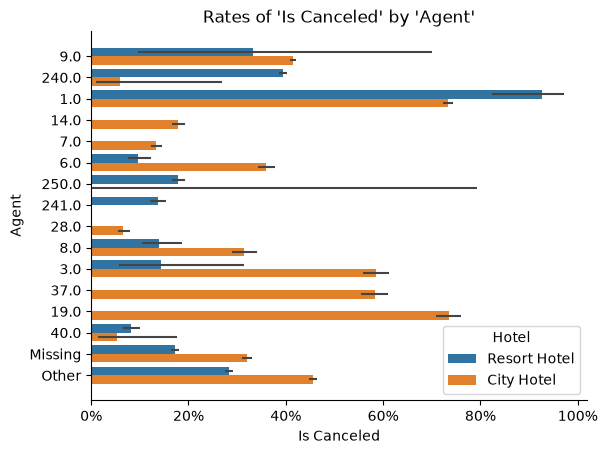

In [32]:
grouped_barplot(df, 'agent', 'is_canceled', 'hotel', categories=frequent_agents + ['Missing'], other='Other')

In [33]:
companies = df['company'].value_counts()
frequent_companies = companies[companies > 100].index.tolist()

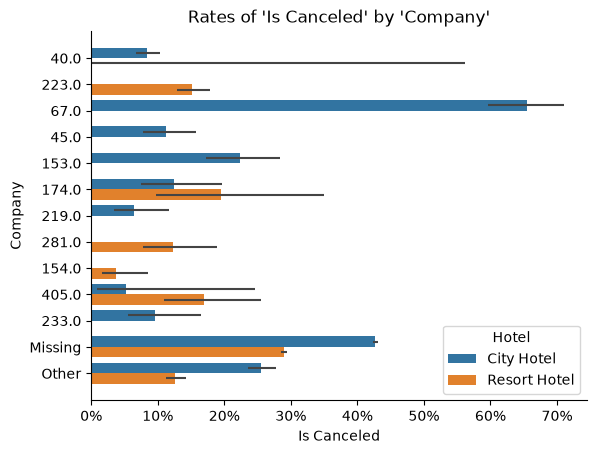

In [34]:
grouped_barplot(df, 'company', 'is_canceled', 'hotel', categories=frequent_companies + ['Missing'], other='Other')

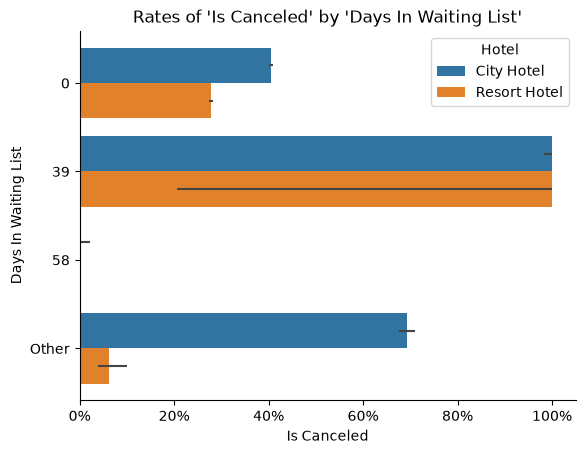

In [35]:
waiting_days = df['days_in_waiting_list'].value_counts()
frequent_waiting_days = waiting_days[waiting_days > 150].index.tolist()
grouped_barplot(df, 'days_in_waiting_list', 'is_canceled', 'hotel', categories=frequent_waiting_days, other='Other')

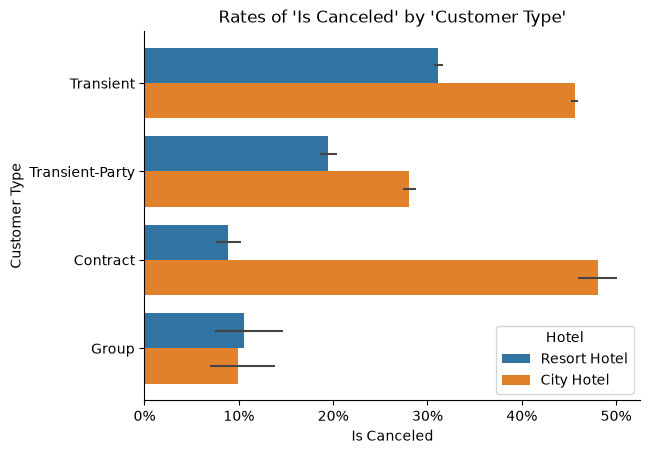

In [36]:
grouped_barplot(df, 'customer_type', 'is_canceled', 'hotel')

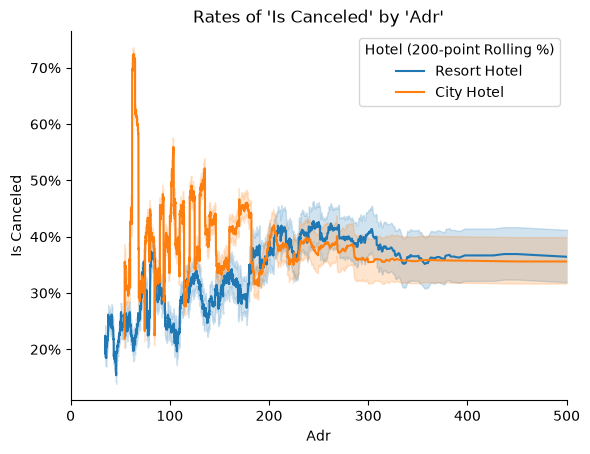

In [37]:
grouped_lineplot(df, 'adr', 'is_canceled', 'hotel', rolling_period=200, xlim=(0, 500))

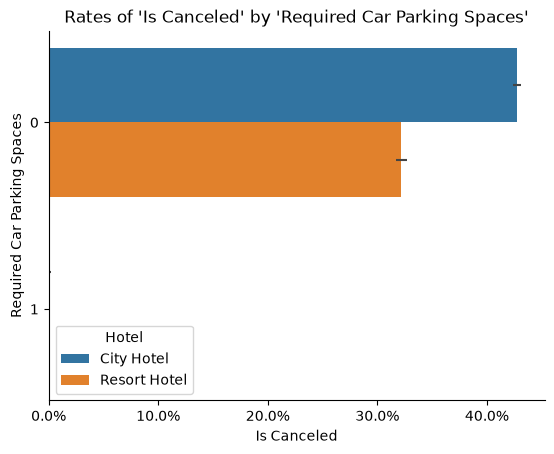

In [38]:
grouped_barplot(df, 'required_car_parking_spaces', 'is_canceled', 'hotel', categories=[0, 1])

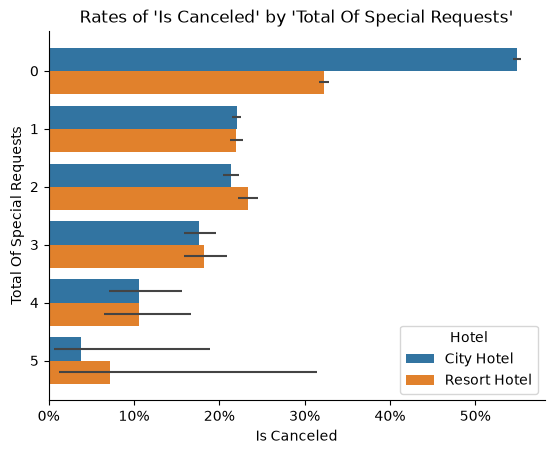

In [39]:
grouped_barplot(df, 'total_of_special_requests', 'is_canceled', 'hotel')

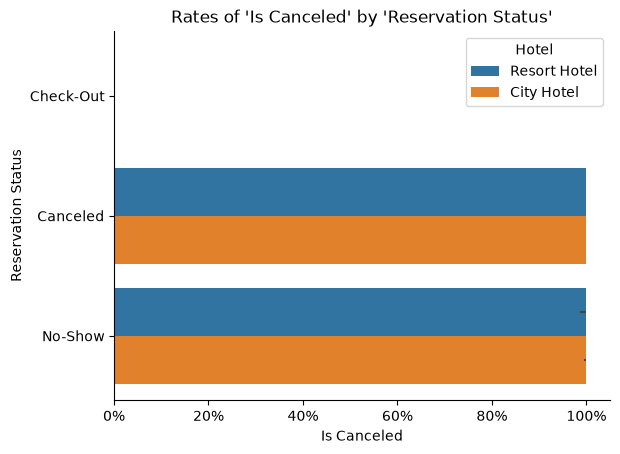

In [40]:
grouped_barplot(df, 'reservation_status', 'is_canceled', 'hotel')

In [41]:
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

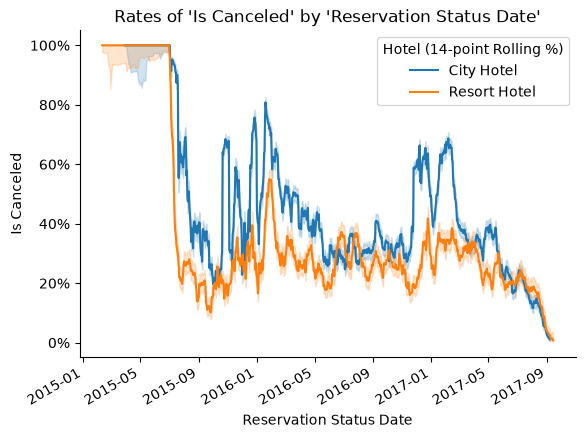

In [42]:
grouped_lineplot(df, 'reservation_status_date', 'is_canceled', 'hotel', rolling_period=14)

In [43]:
df['reservations_status_month_and_day'] = pd.to_datetime(
    '2000-' + df['reservation_status_date'].dt.strftime('%m-%d'),
    format='%Y-%m-%d'
)

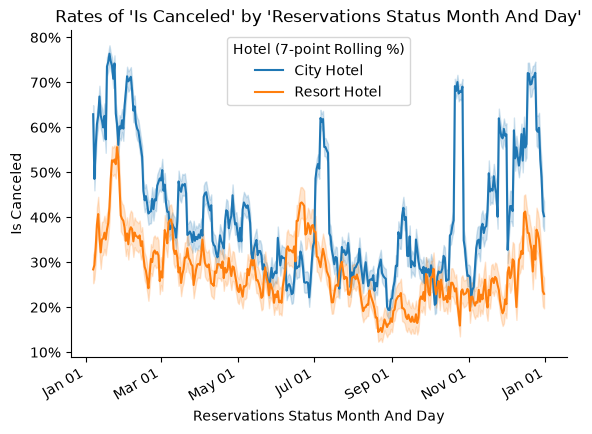

In [44]:
grouped_lineplot(df, 'reservations_status_month_and_day', 'is_canceled', 'hotel', rolling_period=7, remove_year=True)